# Análise exploratória inicial — recomendação de cultivo inteligente

**Disciplina:** Data Challenge  
**Desafio escolhido:** Desafio 2 — Recomendação de cultivo inteligente (dados tabulares)  
**Etapa:** Entrega 1 — definição e análise inicial

Este notebook apresenta uma primeira leitura da base pública `randalakab/Crop-recommendation`. O objetivo é compreender sua estrutura, verificar a qualidade dos dados, explorar relações entre as variáveis e reproduzir um experimento inicial simples, coerente com o relatório da Entrega 1.

## 1. Pergunta de pesquisa

**Em que medida os teores de nitrogênio, fósforo e potássio, combinados com temperatura, umidade, pH e precipitação, permitem identificar a cultura mais compatível entre as 22 classes da base?**

Nesta etapa inicial, buscamos:

1. documentar como os dados foram obtidos;
2. conhecer dimensões, tipos e distribuição das variáveis;
3. identificar ausências, duplicidades e valores que merecem investigação;
4. observar quais atributos mais diferenciam as culturas;
5. construir um primeiro modelo apenas como verificação de viabilidade.

In [1]:
from pathlib import Path
from urllib.request import urlopen
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

Raiz do projeto: /workspace


In [ ]:
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)

RANDOM_STATE = 42
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
TARGET = "label"

current_dir = Path.cwd().resolve()
PROJECT_ROOT = current_dir.parent if current_dir.name == "notebooks" else current_dir
DATA_DIR = PROJECT_ROOT / "data"
FIGURES_DIR = PROJECT_ROOT / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

print(f"Raiz do projeto: {PROJECT_ROOT}")

## 2. Obtenção dos dados

O notebook consulta a API do Hugging Face para identificar o CSV publicado no dataset.

In [2]:
DATASET_ID = "randalakab/Crop-recommendation"
API_URL = f"https://huggingface.co/api/datasets/{DATASET_ID}"
LOCAL_FALLBACK = DATA_DIR / "crop_recommendation.csv"

try:
    with urlopen(API_URL, timeout=30) as response:
        dataset_info = json.load(response)
    csv_files = [item["rfilename"] for item in dataset_info["siblings"]
                 if item["rfilename"].lower().endswith(".csv")]
    selected_file = csv_files[0]
    data_url = f"https://huggingface.co/datasets/{DATASET_ID}/resolve/main/{selected_file}"
    df = pd.read_csv(data_url)
    source_used = data_url
except Exception as error:
    if not LOCAL_FALLBACK.exists():
        raise RuntimeError("A API falhou e não existe CSV local de contingência.") from error
    selected_file = LOCAL_FALLBACK.name
    source_used = str(LOCAL_FALLBACK)
    dataset_info = {}
    df = pd.read_csv(LOCAL_FALLBACK)

provenance = pd.Series({
    "dataset": DATASET_ID,
    "arquivo": selected_file,
    "fonte utilizada": source_used,
    "revisão informada pela API": dataset_info.get("sha", "não informada"),
    "última modificação": dataset_info.get("lastModified", "não informada"),
}, name="valor")

display(provenance.to_frame())
display(df.head())
print(f"Dimensões: {df.shape[0]:,} linhas × {df.shape[1]} colunas")

,valor
dataset,randalakab/Crop-recommendation
arquivo,crop_recommendation.csv
fonte utilizada,https://huggingface.co/datasets/randalakab/Cro...
revisão informada pela API,f154ba9e2c812c86ec6e24e9bfa14803d6db9689
última modificação,2026-03-18T05:15:09.000Z


,N,P,K,temperature,humidity,ph,rainfall,label
0,93.183761,27.250831,74.277207,33.674623,94.914503,6.484254,32.683787,muskmelon
1,96.207721,19.879799,58.311558,30.074946,87.959344,6.755477,41.108275,watermelon
2,43.282444,20.270145,46.187129,34.166159,100.166220,7.390471,197.558965,papaya
3,59.798590,4.900153,41.490719,26.914239,92.876518,6.929745,147.476051,papaya
4,6.924168,137.545829,169.587918,23.536649,94.791895,5.777406,192.413493,apple


Dimensões: 2,200 linhas × 8 colunas


## 3. Diagnóstico inicial de qualidade

In [3]:
diagnostico = pd.Series({
    "registros": len(df),
    "colunas": df.shape[1],
    "valores ausentes": int(df.isna().sum().sum()),
    "linhas duplicadas": int(df.duplicated().sum()),
    "culturas": int(df[TARGET].nunique()),
    "menor classe": int(df[TARGET].value_counts().min()),
    "maior classe": int(df[TARGET].value_counts().max()),
    "umidade acima de 100": int((df["humidity"] > 100).sum()),
}, name="resultado")

qualidade_colunas = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "ausentes": df.isna().sum(),
    "valores distintos": df.nunique(),
})

display(diagnostico.to_frame())
display(qualidade_colunas)

,resultado
registros,2200
colunas,8
valores ausentes,0
linhas duplicadas,0
culturas,22
menor classe,100
maior classe,100
umidade acima de 100,19


,tipo,ausentes,valores distintos
N,float64,0,2180
P,float64,0,2200
K,float64,0,2200
temperature,float64,0,2200
humidity,float64,0,2200
ph,float64,0,2200
rainfall,float64,0,2200
label,str,0,22


O conjunto está completo, sem duplicidades e perfeitamente balanceado entre as culturas. Esse equilíbrio é conveniente para a comparação inicial, mas também é um indício de base preparada para fins analíticos. Os 19 registros com umidade acima de 100 exigem verificação de unidade ou de método de medição; eles não serão removidos automaticamente.

## 4. Estatísticas descritivas

In [4]:
resumo = df[FEATURES].describe().T
resumo["amplitude"] = resumo["max"] - resumo["min"]
display(resumo.round(2))

,count,mean,std,min,25%,50%,75%,max,amplitude
N,2200.0,48.25,39.37,0.00,14.69,32.01,85.45,140.72,140.72
P,2200.0,48.45,31.71,0.00,23.45,44.60,61.33,152.12,152.12
K,2200.0,61.04,42.32,2.67,41.75,51.42,61.20,240.58,237.91
temperature,2200.0,25.57,6.23,0.83,22.01,26.12,29.62,41.73,40.90
humidity,2200.0,72.56,22.63,13.61,61.60,79.96,89.68,101.36,87.76
ph,2200.0,6.42,0.68,3.56,6.05,6.43,6.86,8.02,4.47
rainfall,2200.0,114.36,61.20,18.26,65.52,99.13,157.75,301.95,283.69


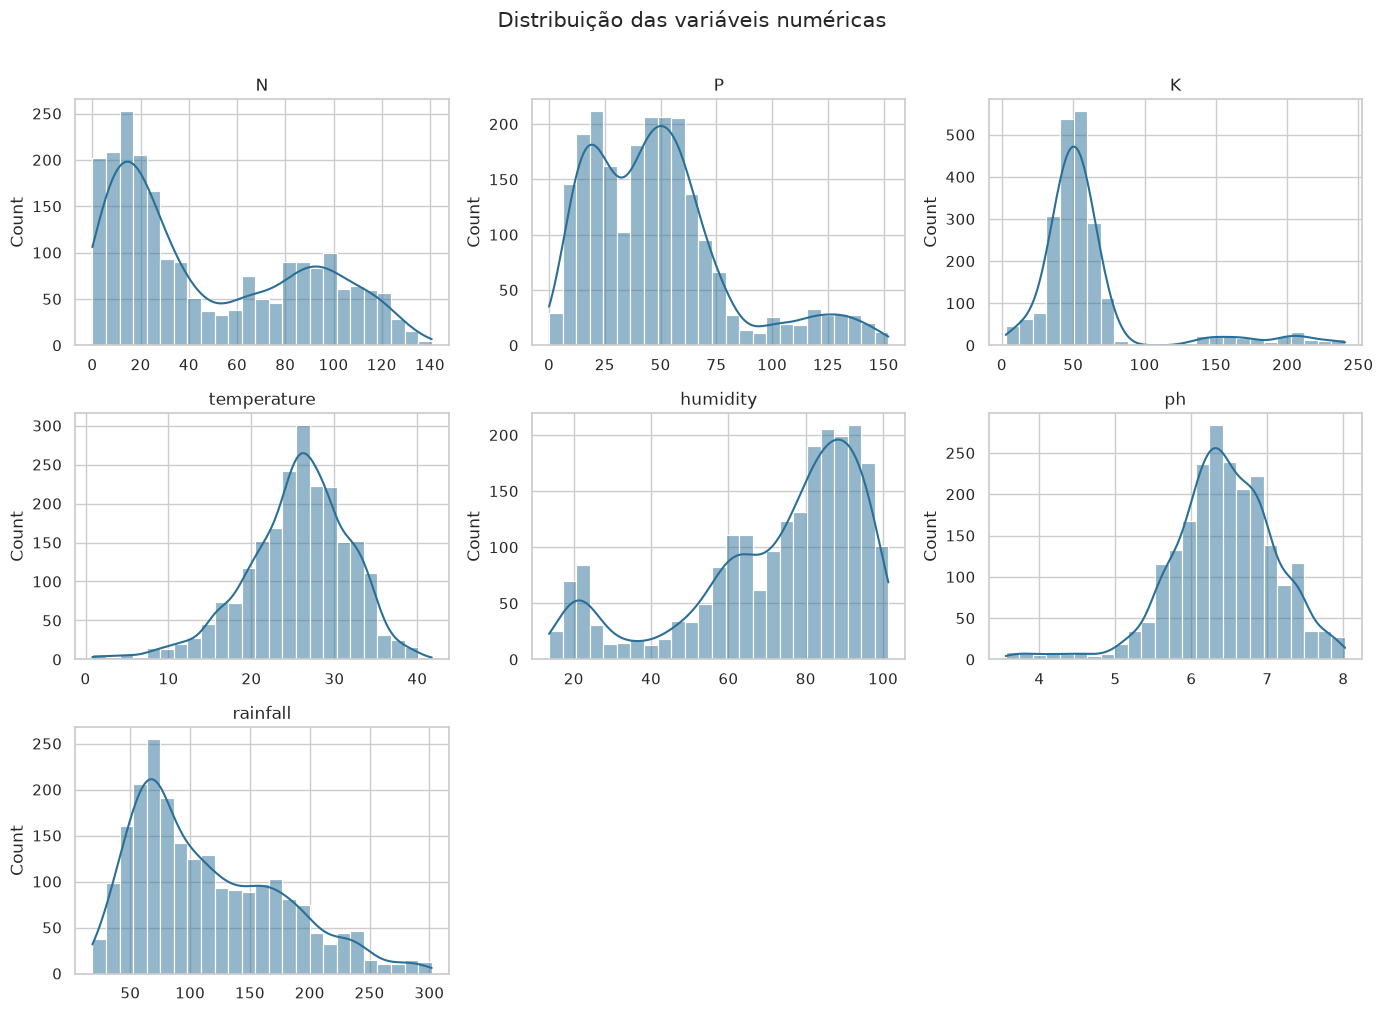

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, feature in zip(axes.flat, FEATURES):
    sns.histplot(df[feature], bins=25, kde=True, ax=ax, color="#2A6F97")
    ax.set_title(feature)
    ax.set_xlabel("")
for ax in axes.flat[len(FEATURES):]:
    ax.axis("off")
fig.suptitle("Distribuição das variáveis numéricas", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

## 5. Distribuição das culturas

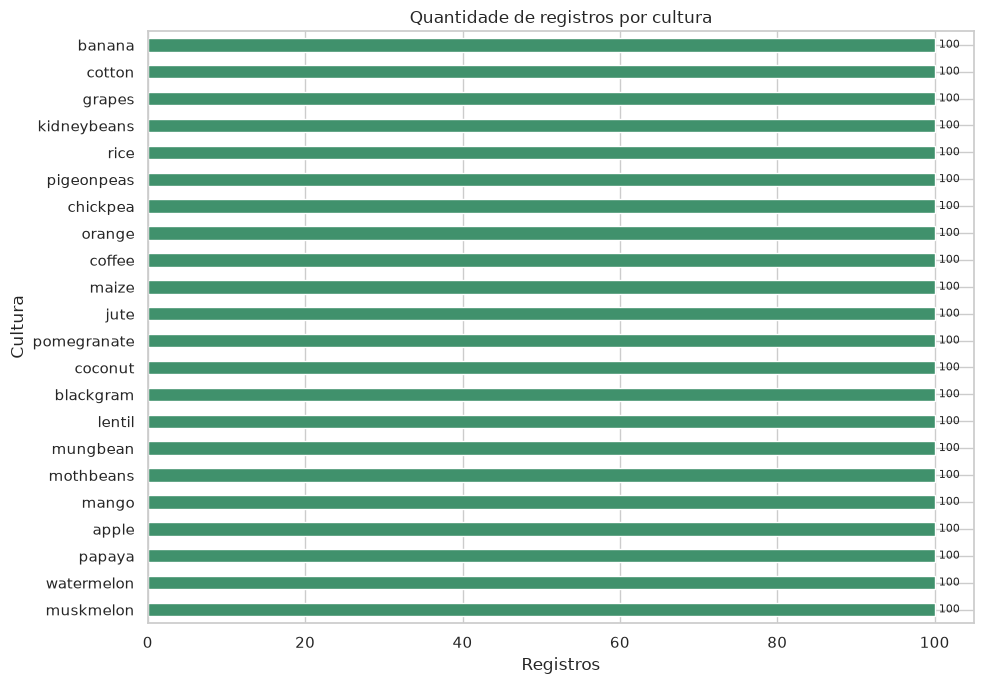

Cada uma das 22 culturas possui 100 registros.


In [6]:
contagem = df[TARGET].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
contagem.plot.barh(ax=ax, color="#40916C")
ax.set(title="Quantidade de registros por cultura", xlabel="Registros", ylabel="Cultura")
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
plt.tight_layout()
plt.show()

print(f"Cada uma das {df[TARGET].nunique()} culturas possui {contagem.iloc[0]} registros.")

## 6. Relações entre as variáveis

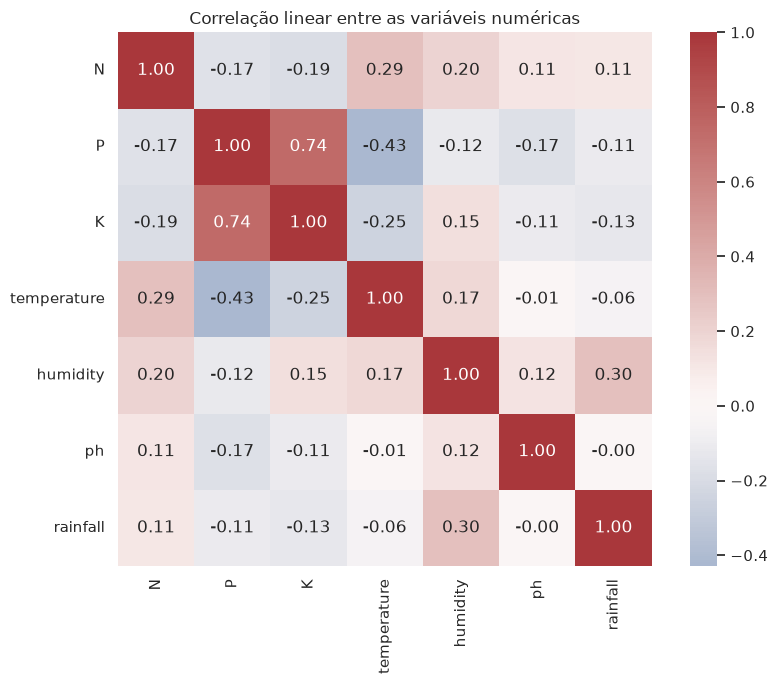

In [7]:
corr = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, ax=ax)
ax.set_title("Correlação linear entre as variáveis numéricas")
plt.tight_layout()
plt.show()

Como a variável de interesse é categórica, a correlação entre atributos não mostra sozinha o poder de separação das culturas. Para complementar, calculamos o eta quadrado, que representa a proporção da variação de cada atributo associada às diferenças entre as classes. É uma medida exploratória, não uma prova de causalidade.

def eta_squared(data, feature, target):
    overall_mean = data[feature].mean()
    total_variation = ((data[feature] - overall_mean) ** 2).sum()
    between_groups = sum(
        len(group) * (group[feature].mean() - overall_mean) ** 2
        for _, group in data.groupby(target)
    )
    return between_groups / total_variation

eta = pd.Series(
    {feature: eta_squared(df, feature, TARGET) for feature in FEATURES},
    name="eta_quadrado",
).sort_values()

display(eta.sort_values(ascending=False).to_frame().round(4))
fig, ax = plt.subplots(figsize=(8, 4))
eta.plot.barh(ax=ax, color="#E9C46A")
ax.set(title="Separação exploratória das culturas por variável", xlabel="Eta quadrado", ylabel="")
plt.tight_layout()
plt.show()

## 7. Ponto de atenção: valores de umidade

,N,P,K,temperature,humidity,ph,rainfall,label
2149,14.803819,149.121607,147.057008,14.764585,101.362240,5.643967,169.286577,apple
1293,24.307783,19.123312,42.473961,33.540762,101.191800,5.530988,146.024671,coconut
1419,8.696370,13.530375,15.969660,10.210177,101.146861,6.273814,148.437585,orange
376,16.741278,139.066097,176.448148,10.344184,100.725121,6.334881,130.829449,apple
1149,115.389101,12.639566,53.772282,37.640039,100.698368,6.059751,32.738388,muskmelon
508,43.467672,9.558881,56.667697,37.883718,100.676138,6.939354,104.455039,papaya
651,68.203988,7.140359,40.641077,28.029511,100.621739,7.482378,166.517754,papaya
2044,9.960152,9.801056,11.864105,28.691512,100.596350,7.070096,186.137927,orange
1677,29.932057,15.351319,58.786580,26.324554,100.574521,6.731762,104.613829,coconut
753,6.981524,9.940116,13.441539,16.189667,100.551704,7.216624,117.114812,orange


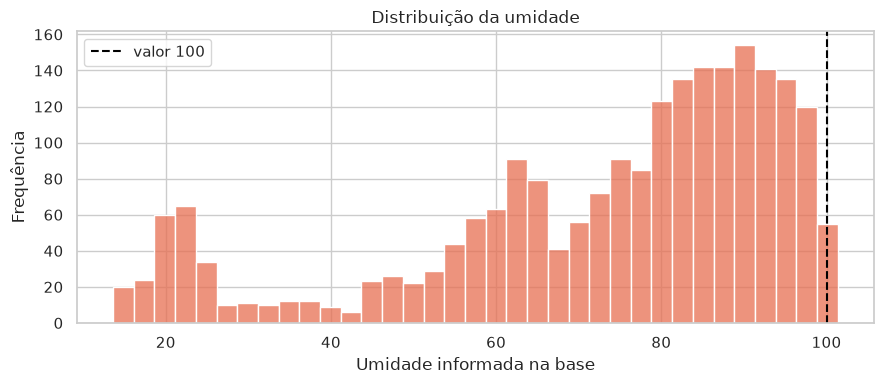

In [9]:
humidity_over_100 = df.loc[df["humidity"] > 100].sort_values("humidity", ascending=False)
display(humidity_over_100)

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df["humidity"], bins=35, color="#E76F51", ax=ax)
ax.axvline(100, color="black", linestyle="--", label="valor 100")
ax.set(title="Distribuição da umidade", xlabel="Umidade informada na base", ylabel="Frequência")
ax.legend()
plt.tight_layout()
plt.show()

Sem a documentação da unidade e do processo de coleta, não é possível concluir que esses registros sejam erros. Por isso, a decisão inicial é mantê-los e registrar a necessidade de confirmação com a fonte dos dados.

## 8. Experimento inicial de viabilidade

Para verificar se existe sinal preditivo, separamos 20% dos registros para teste e comparamos quatro alternativas. A seleção usa validação cruzada estratificada em cinco partes **somente no conjunto de treino**, com F1 macro, métrica que atribui o mesmo peso a cada cultura.

Esta seção não pretende encerrar a modelagem. Ela apenas reproduz o primeiro experimento apresentado no relatório.

In [10]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Regressão logística": Pipeline([
        ("padronizacao", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
    ]),
    "Árvore de decisão": DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=2, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, n_jobs=-1, random_state=RANDOM_STATE
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
        n_jobs=1,
    )
    rows.append({
        "modelo": name,
        "acurácia média": scores["test_accuracy"].mean(),
        "F1 macro médio": scores["test_f1_macro"].mean(),
        "desvio-padrão F1": scores["test_f1_macro"].std(),
    })

resultados = pd.DataFrame(rows).sort_values("F1 macro médio", ascending=False)
display(resultados.round(4))

,modelo,acurácia média,F1 macro médio,desvio-padrão F1
3,Random Forest,0.9653,0.9652,0.0069
1,Regressão logística,0.9267,0.9254,0.0108
2,Árvore de decisão,0.9102,0.9096,0.0067
0,Baseline,0.0455,0.0040,0.0000


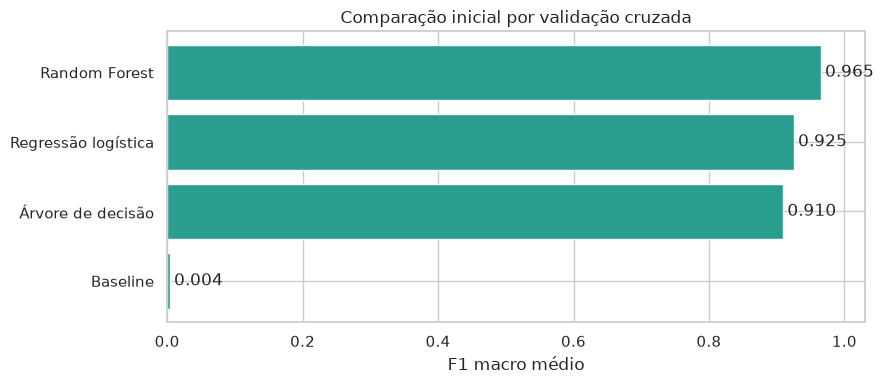

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_data = resultados.sort_values("F1 macro médio")
ax.barh(plot_data["modelo"], plot_data["F1 macro médio"], color="#2A9D8F")
ax.set(title="Comparação inicial por validação cruzada", xlabel="F1 macro médio", ylabel="")
ax.set_xlim(0, 1.03)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
plt.tight_layout()
plt.show()

In [12]:
modelo_final = models["Random Forest"]
modelo_final.fit(X_train, y_train)
predicoes = modelo_final.predict(X_test)

metricas_teste = pd.Series({
    "acurácia": accuracy_score(y_test, predicoes),
    "precisão macro": precision_score(y_test, predicoes, average="macro", zero_division=0),
    "recall macro": recall_score(y_test, predicoes, average="macro", zero_division=0),
    "F1 macro": f1_score(y_test, predicoes, average="macro"),
    "erros": int((predicoes != y_test).sum()),
    "observações de teste": len(y_test),
}, name="resultado")

importancia = pd.Series(
    modelo_final.feature_importances_, index=FEATURES, name="importância"
).sort_values(ascending=False)

display(metricas_teste.to_frame())
display(importancia.to_frame().round(4))

,resultado
acurácia,0.972727
precisão macro,0.974366
recall macro,0.972727
F1 macro,0.972464
erros,12.000000
observações de teste,440.000000


,importância
humidity,0.2384
P,0.1616
rainfall,0.1586
N,0.1492
K,0.1251
ph,0.0905
temperature,0.0767


### 8.1 Principais confusões e sensibilidade da umidade

Para tornar os resultados do relatório diretamente verificáveis, observamos quais pares de culturas concentram os erros e repetimos uma validação cruzada diagnóstica com e sem os 19 registros de umidade acima de 100. A sensibilidade não redefine o modelo escolhido; serve apenas para verificar se esses registros alteram substancialmente o resultado.

In [13]:
erros_teste = pd.DataFrame({
    "cultura_real": y_test.to_numpy(),
    "cultura_prevista": predicoes,
}).query("cultura_real != cultura_prevista")

principais_confusoes = (
    erros_teste.value_counts(["cultura_real", "cultura_prevista"])
    .rename("quantidade")
    .reset_index()
)

display(principais_confusoes.head(10))
print(f"Total de erros no teste: {len(erros_teste)} de {len(y_test)} observações")

,cultura_real,cultura_prevista,quantidade
0,kidneybeans,chickpea,5
1,chickpea,kidneybeans,1
2,rice,banana,1
3,pomegranate,coconut,1
4,pigeonpeas,blackgram,1
5,jute,rice,1
6,rice,jute,1
7,pigeonpeas,lentil,1


Total de erros no teste: 12 de 440 observações


In [14]:
df_sem_umidade_extrema = df.loc[df["humidity"] <= 100].copy()

scores_base_completa = cross_validate(
    RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=RANDOM_STATE),
    df[FEATURES], df[TARGET], cv=cv, scoring="f1_macro", n_jobs=1,
)["test_score"]

scores_base_filtrada = cross_validate(
    RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=RANDOM_STATE),
    df_sem_umidade_extrema[FEATURES], df_sem_umidade_extrema[TARGET],
    cv=cv, scoring="f1_macro", n_jobs=1,
)["test_score"]

sensibilidade = pd.DataFrame({
    "cenário": ["Base completa", "Sem umidade acima de 100"],
    "registros": [len(df), len(df_sem_umidade_extrema)],
    "F1 macro médio": [scores_base_completa.mean(), scores_base_filtrada.mean()],
    "desvio-padrão": [scores_base_completa.std(), scores_base_filtrada.std()],
})

display(sensibilidade.round(4))

,cenário,registros,F1 macro médio,desvio-padrão
0,Base completa,2200,0.9680,0.0058
1,Sem umidade acima de 100,2181,0.9712,0.0101


## 9. Conclusões da primeira análise

- A base possui **2.200 registros, sete atributos preditores e 22 culturas**, com 100 exemplos por classe.
- Não foram encontrados valores ausentes nem linhas duplicadas.
- O balanceamento perfeito facilita a comparação, mas a representatividade de situações agrícolas reais ainda não está demonstrada.
- Os 19 valores de umidade acima de 100 precisam ser esclarecidos; sem metadados, não devem ser excluídos automaticamente.
- O experimento inicial indica que as variáveis contêm sinal suficiente para distinguir as culturas dentro desta base. O Random Forest obteve desempenho muito superior ao baseline.
- O desempenho interno elevado não comprova capacidade de recomendar cultivos para uma região real, pois faltam informações de localização, período, unidades e processo de coleta.

### Próximos passos

1. confirmar a procedência e as unidades dos atributos;
2. investigar os registros de umidade e documentar a decisão de tratamento;
3. analisar com mais detalhe os erros entre culturas semelhantes;
4. ajustar hiperparâmetros sem utilizar o conjunto de teste;
5. buscar dados regionais de solo e clima para uma validação externa;
6. discutir critérios agronômicos e limitações de uso da recomendação.